# The Promotion Paradox — Data Prep + Visualization Setup

This notebook intentionally contains only:

1. data loading / cleaning,
2. filtering and transformations needed for the two draft visualizations,
3. lightweight setup code for the two visualizations.

It does **not** include the later year-adjustment diagnostic, interpretation, ethical reflection, or final prose.


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "allegations_202007271729.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")


Rows: 33,358
Columns: 27


## 1. Keep the variables needed for the two drafts


In [14]:
cols = [
    "unique_mos_id",
    "complaint_id",
    "year_received",
    "rank_incident",
    "board_disposition",
]

data = df[cols].copy()

data.head()


,unique_mos_id,complaint_id,year_received,rank_incident,board_disposition
0,10004,42835,2019,Police Officer,Substantiated (Command Lvl Instructions)
1,10007,24601,2011,Police Officer,Substantiated (Charges)
2,10007,24601,2011,Police Officer,Substantiated (Charges)
3,10007,26146,2012,Police Officer,Substantiated (Charges)
4,10009,40253,2018,Police Officer,Substantiated (Command Discipline A)


## 2. Clean rank and disposition fields

Each row in this dataset is an **allegation**.  
For these drafts, an allegation is coded as substantiated when `board_disposition`
starts with `"Substantiated"`.


In [15]:
data["rank_incident"] = data["rank_incident"].astype("string").str.strip()
data["board_disposition"] = data["board_disposition"].astype("string").str.strip()

data["substantiated"] = (
    data["board_disposition"]
        .str.lower()
        .str.startswith("substantiated", na=False)
)

data["substantiated"] = data["substantiated"].astype(int)

data[["rank_incident", "board_disposition", "substantiated"]].head()


,rank_incident,board_disposition,substantiated
0,Police Officer,Substantiated (Command Lvl Instructions),1
1,Police Officer,Substantiated (Charges),1
2,Police Officer,Substantiated (Charges),1
3,Police Officer,Substantiated (Charges),1
4,Police Officer,Substantiated (Command Discipline A),1


# Visualization 1 setup
## Officer-weighted substantiation rate by rank

The first draft compares **average officer-level substantiation rates** for:

- Police Officer
- Sergeant
- Lieutenant

First, calculate each officer's substantiation rate separately at each rank. Then average those officer-level rates within each rank, so **each officer receives equal weight**.


In [16]:
rank_order = ["Police Officer", "Sergeant", "Lieutenant"]

viz1_source = data[
    data["rank_incident"].isin(rank_order)
].copy()


officer_rank_rates = (
    viz1_source
    .groupby(["unique_mos_id", "rank_incident"], observed=True)
    ["substantiated"]
    .mean()
    .reset_index(name="officer_substantiation_rate")
)


viz1_data = (
    officer_rank_rates
    .groupby("rank_incident", observed=True)
    .agg(
        num_officers=("unique_mos_id", "nunique"),
        substantiation_rate=("officer_substantiation_rate", "mean"),
    )
    .reindex(rank_order)
    .reset_index()
)

viz1_data["substantiation_pct"] = 100 * viz1_data["substantiation_rate"]

viz1_data


,rank_incident,num_officers,substantiation_rate,substantiation_pct
0,Police Officer,3606,0.373332,37.333171
1,Sergeant,852,0.309019,30.901862
2,Lieutenant,213,0.237480,23.747996


### Draft Visualization 1

The bars share a common 0% baseline, and bar length represents the **average officer-level substantiation rate** at each rank.


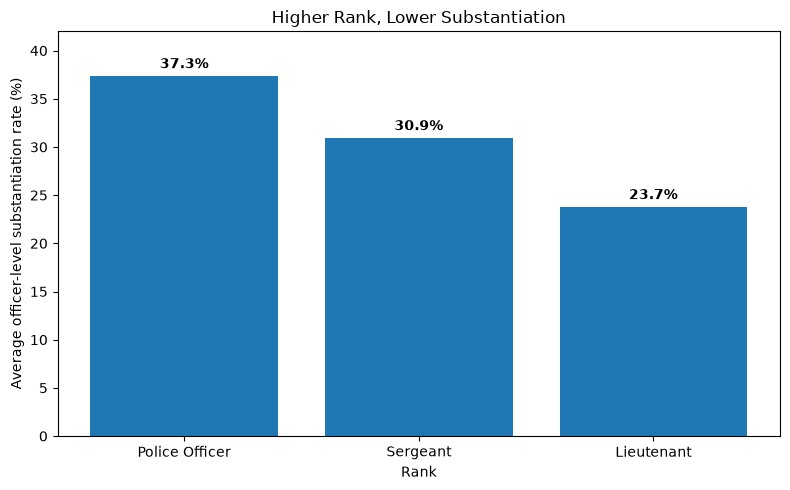

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    viz1_data["rank_incident"],
    viz1_data["substantiation_pct"]
)

# Add percentage labels above bars
for bar, rate in zip(bars, viz1_data["substantiation_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{rate:.1f}%",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_xlabel("Rank")
ax.set_ylabel("Average officer-level substantiation rate (%)")
ax.set_title("Higher Rank, Lower Substantiation")

# Start at zero
ax.set_ylim(0, 42)

plt.tight_layout()
plt.show()

# Visualization 2 setup
## Same officers observed as both Police Officer and Sergeant

The final displayed rates are **equal-weight officer-level means**: each matched
officer contributes one Police Officer rate and one Sergeant rate.


In [18]:
po_sgt = data[
    data["rank_incident"].isin(["Police Officer", "Sergeant"])
].copy()

officer_rank = (
    po_sgt
    .groupby(["unique_mos_id", "rank_incident"], observed=True)
    .agg(
        allegations=("substantiated", "size"),
        substantiated_allegations=("substantiated", "sum"),
        substantiation_rate=("substantiated", "mean"),
        first_year=("year_received", "min"),
        last_year=("year_received", "max"),
    )
    .reset_index()
)

officer_rank.head()


,unique_mos_id,rank_incident,allegations,substantiated_allegations,substantiation_rate,first_year,last_year
0,2,Sergeant,10,1,0.1,2009,2013
1,5,Police Officer,1,0,0.0,2011,2011
2,5,Sergeant,2,1,0.5,2015,2016
3,11,Police Officer,5,2,0.4,2007,2012
4,21,Police Officer,8,4,0.5,2006,2011


In [19]:
wide = officer_rank.pivot(
    index="unique_mos_id",
    columns="rank_incident",
    values=[
        "allegations",
        "substantiation_rate",
        "first_year",
        "last_year",
    ],
)

wide.head()

allegations          substantiation_rate           \
rank_incident Police Officer Sergeant      Police Officer Sergeant   
unique_mos_id                                                        
2                        NaN     10.0                 NaN      0.1   
5                        1.0      2.0            0.000000      0.5   
11                       5.0      NaN            0.400000      NaN   
21                       8.0      NaN            0.500000      NaN   
23                      14.0      NaN            0.071429      NaN   

                  first_year               last_year           
rank_incident Police Officer Sergeant Police Officer Sergeant  
unique_mos_id                                                  
2                        NaN   2009.0            NaN   2013.0  
5                     2011.0   2015.0         2011.0   2016.0  
11                    2007.0      NaN         2012.0      NaN  
21                    2006.0      NaN         2011.0      NaN  
23                    2008.0      NaN         2013.0      NaN

In [20]:
# Keep officers observed at BOTH ranks.
matched = wide.dropna(
    subset=[
        ("substantiation_rate", "Police Officer"),
        ("substantiation_rate", "Sergeant"),
    ]
).copy()


# first observed Sergeant year is not earlier than first observed Police Officer year
matched = matched[
    matched[("first_year", "Sergeant")]
    >= matched[("first_year", "Police Officer")]
].copy()

print(f"Matched officers: {len(matched):,}")
matched.head()


Matched officers: 594


allegations          substantiation_rate           \
rank_incident Police Officer Sergeant      Police Officer Sergeant   
unique_mos_id                                                        
5                        1.0      2.0            0.000000      0.5   
208                      3.0      1.0            0.666667      0.0   
216                      1.0      1.0            0.000000      0.0   
289                      1.0      1.0            0.000000      1.0   
513                      4.0      1.0            0.500000      0.0   

                  first_year               last_year           
rank_incident Police Officer Sergeant Police Officer Sergeant  
unique_mos_id                                                  
5                     2011.0   2015.0         2011.0   2016.0  
208                   2007.0   2017.0         2008.0   2017.0  
216                   2006.0   2013.0         2006.0   2013.0  
289                   2012.0   2017.0         2012.0   2017.0  
513                   2009.0   2014.0         2010.0   2014.0

In [21]:
viz2_data = pd.DataFrame({
    "rank": ["Police Officer", "Sergeant"],
    "mean_officer_substantiation_pct": [
        100 * matched[("substantiation_rate", "Police Officer")].mean(),
        100 * matched[("substantiation_rate", "Sergeant")].mean(),
    ],
})

viz2_data["difference_from_po_pp"] = (
    viz2_data["mean_officer_substantiation_pct"]
    - viz2_data.loc[
        viz2_data["rank"] == "Police Officer",
        "mean_officer_substantiation_pct"
    ].iloc[0]
)

viz2_data


,rank,mean_officer_substantiation_pct,difference_from_po_pp
0,Police Officer,16.536242,0.000000
1,Sergeant,25.236615,8.700373


### Draft Visualization 2

This prototype emphasizes that the comparison uses the **same matched officers**.


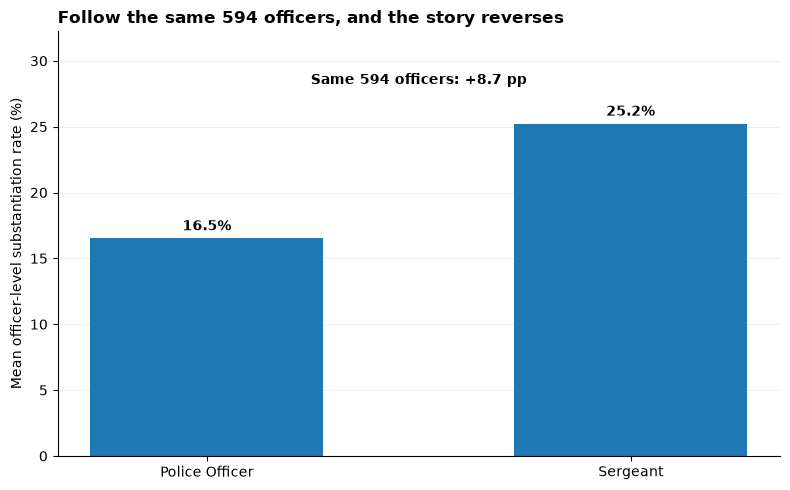

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(viz2_data))
rates = viz2_data["mean_officer_substantiation_pct"].to_numpy()

ax.bar(x, rates, width=0.55)

for xi, rate in zip(x, rates):
    ax.text(xi, rate + 0.6, f"{rate:.1f}%", ha="center", fontweight="bold")

difference = rates[1] - rates[0]
ax.text(
    0.5,
    max(rates) + 3.0,
    f"Same {len(matched):,} officers: +{difference:.1f} pp",
    ha="center",
    fontweight="bold",
)

ax.set_xticks(x, viz2_data["rank"])
ax.set_ylabel("Mean officer-level substantiation rate (%)")
ax.set_ylim(0, max(rates) + 7)
ax.set_title(
    f"Follow the same {len(matched):,} officers, and the story reverses",
    loc="left",
    fontweight="bold",
)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## Prepared objects

The main objects ready for later visualization work are:

- `officer_rank_rates` — one officer-level substantiation rate per officer/rank combination
- `viz1_data` — equal-weight officer-level rates for Police Officer, Sergeant, and Lieutenant
- `matched` — matched Police Officer / Sergeant records for officers observed at both ranks
- `viz2_data` — equal-weight matched-officer rates for the two ranks
